# MSH 3-T-junction array: tensor networks vs exact diagonalization

Compares the two implementations of the 3-T-junction array, number by number:

| Files | Written by | Method |
|---|---|---|
| `msh_array_ldos_tn.csv` | `msh_tjunctions_tn.ipynb` (Julia, TensorBinding), section 5 | DMRG subgap states |
| `msh_gate_density_tdvp_{Z,X}.csv`, `msh_gate_dQ_tdvp_{Z,X}.csv`, `msh_tjunctions_tn_gates.csv` | `msh_tjunctions_tn.ipynb`, sections 6 and 8 | MPS/TDVP evolution with the MPO |
| `tjunctions_python_ed_data/*.npz` | `tjunctions_python_ed.ipynb` (Python, kwant) | dense exact diagonalization and exact evolution |

The CSVs are committed; run `tjunctions_python_ed.ipynb` first, in this directory, to write the `.npz` files. This notebook only loads the
files and compares them, so it runs in seconds.

Each row prints max |Julia − Python| against a tolerance set by the tensor-network method: the DMRG error for the LDOS and the zero modes,
the TDVP error (`maxdim = 64`, $dt = 0.1$) for everything time dependent. The X gate is the run with `rot_Tx = 400`. $\delta n(x, t) = n_1 - n_0$ is
taken on the horizontal chain ($y = 0$, $x = -48 \dots 47$), at the same snapshots in both codes (every 5 time units during the gate, every 1
during the fusion); $\Delta Q(t)$ is summed over all sites.

**Contents**
1. Subgap LDOS
2. MPS/TDVP: δn(x, t) and ΔQ(t)
3. Gate and fusion quantities
4. Cost and scaling
5. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

PY_DIR = "tjunctions_python_ed_data"       # written by tjunctions_python_ed.ipynb

rows = []   # (name, max |Julia − Python|, tolerance)
def check(name, a, b, tol):
    d = float(np.max(np.abs(np.asarray(a) - np.asarray(b))))
    rows.append((name, d, tol))
    print(f"{name:<52s} {d:9.1e}  (tol {tol:.0e})  {'✓' if d <= tol else '✗'}")

def read_csv(name):
    return np.loadtxt(name, delimiter=",", skiprows=1)

def tn_density(name):
    """(t, x) table of a δn CSV (columns t, x, dn; x fastest)."""
    d = read_csv(name)
    ts, xs = np.unique(d[:, 0]), np.unique(d[:, 1])
    return ts, xs, d[:, 2].reshape(ts.size, xs.size)

## 1. Subgap LDOS

Total (particle + hole, spin-summed) LDOS $A(\mathbf r, \omega)$ of the initial setup, Gaussian width 0.01, $|\omega| \le 0.2$, on all 144 sites.
Julia uses the six lowest-|E| states from penalized DMRG (Rayleigh–Ritz in $H$); Python uses every eigenstate of the dense matrix. Inside the
window only those six states contribute, so the difference is the DMRG error.

**Plot.** $A(x, \omega = 0)$ along the horizontal chain, and $A(\omega)$ at the site with the largest zero-energy weight.

LDOS A(r, ω), DMRG (6 states) vs dense                 3.9e-04  (tol 1e-03)  ✓


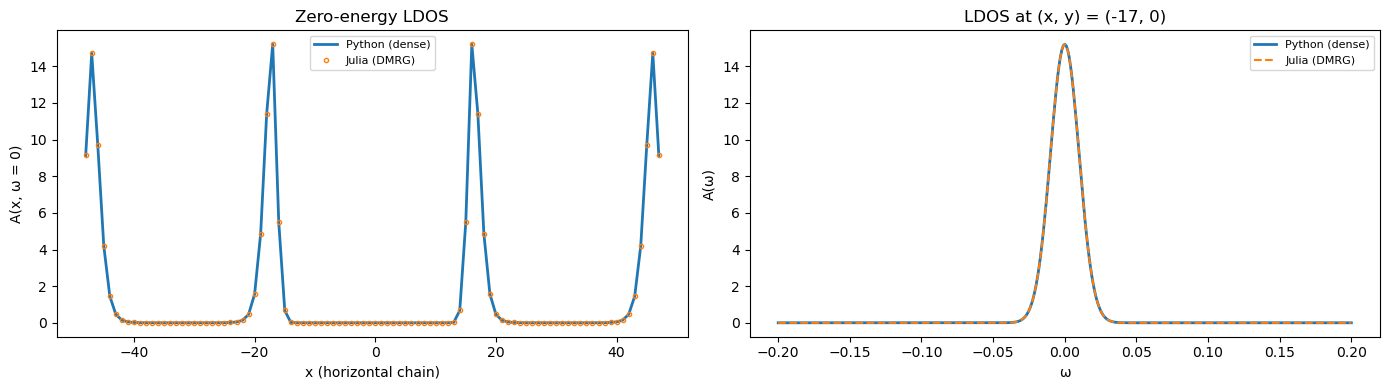

In [2]:
py_l = np.load(os.path.join(PY_DIR, "array_ldos_kwant.npz"))
x, y, om, A_py = py_l["x"], py_l["y"], py_l["omega"], py_l["A"]          # A: (site, ω)
d = read_csv("msh_array_ldos_tn.csv")
tn_map = {(int(r[0]), int(r[1]), round(r[2], 6)): r[3] for r in d}
A_tn = np.array([[tn_map[(int(x[i]), int(y[i]), round(w, 6))] for w in om] for i in range(x.size)])
check("LDOS A(r, ω), DMRG (6 states) vs dense", A_tn, A_py, 1e-3)

j0 = np.argmin(np.abs(om)); h = np.where(y == 0)[0]; h = h[np.argsort(x[h])]; i_max = np.argmax(A_py[:, j0])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(x[h], A_py[h, j0], lw=2, label="Python (dense)")
ax[0].plot(x[h], A_tn[h, j0], "o", ms=3, mfc="none", label="Julia (DMRG)")
ax[0].set(xlabel="x (horizontal chain)", ylabel="A(x, ω = 0)", title="Zero-energy LDOS"); ax[0].legend(fontsize=8)
ax[1].plot(om, A_py[i_max], lw=2, label="Python (dense)")
ax[1].plot(om, A_tn[i_max], "--", lw=1.5, label="Julia (DMRG)")
ax[1].set(xlabel="ω", ylabel="A(ω)", title=f"LDOS at (x, y) = ({x[i_max]}, {y[i_max]})"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 2. MPS/TDVP: δn(x, t) and ΔQ(t)

The TDVP evolution of $\psi_A$, $\psi_B$ (2-site TDVP on the MPO, `maxdim = 64`) over the full gate + fusion protocol, against the Python exact
evolution.

**Plots.** $\log_{10}|\delta n_{\rm TDVP} - \delta n_{\rm Python}|$ over the full protocol (dashed: end of the first exchange and of the gate);
$\Delta Q(t)$ during the fusion (TDVP markers on the Python curves) and $|\Delta Q_{\rm TDVP} - \Delta Q_{\rm Python}|$ over the full protocol.

TDVP δn(x, t), Z gate + fusion                         1.4e-06  (tol 1e-05)  ✓
TDVP ΔQ(t), Z gate + fusion                            3.9e-06  (tol 1e-05)  ✓
TDVP δn(x, t), X gate + fusion                         1.0e-06  (tol 1e-05)  ✓
TDVP ΔQ(t), X gate + fusion                            2.2e-06  (tol 1e-05)  ✓


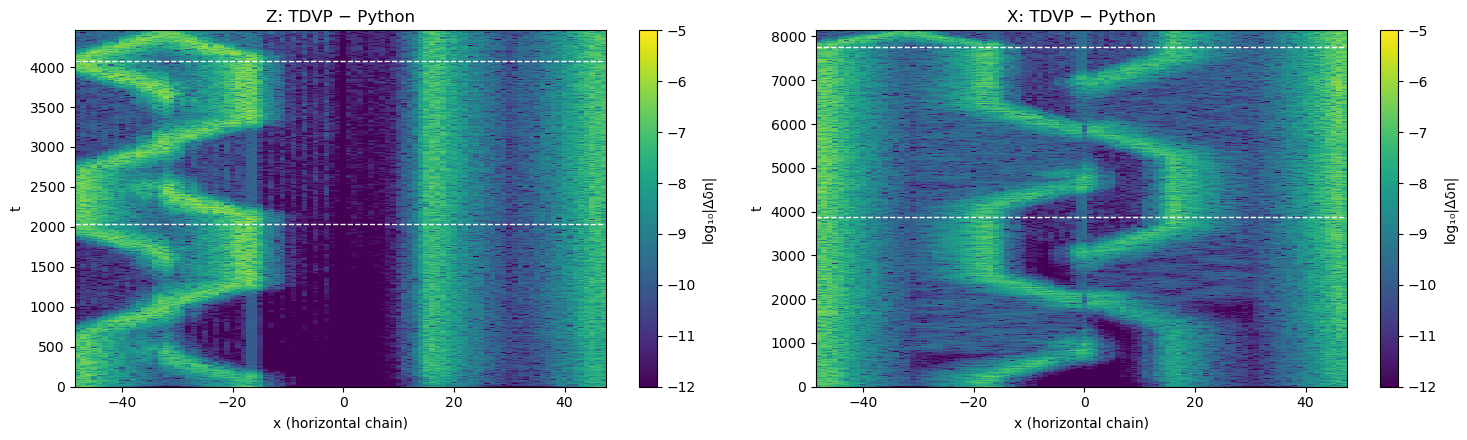

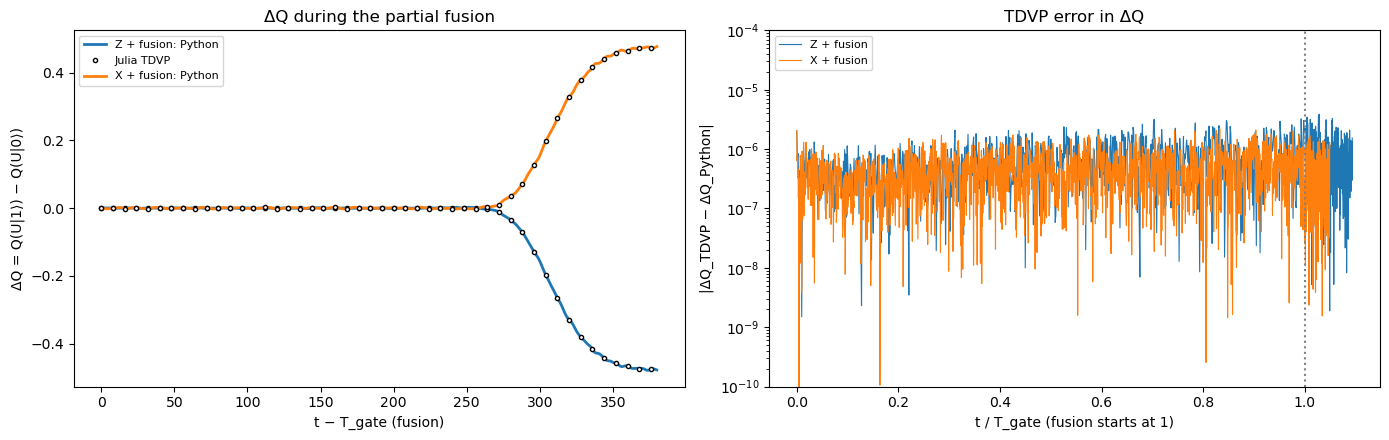

In [3]:
dens = {}
for gate, key in (("Z", "Z"), ("X", "X400")):
    ts, xs_, D_tdvp = tn_density(f"msh_gate_density_tdvp_{gate}.csv")
    dq = read_csv(f"msh_gate_dQ_tdvp_{gate}.csv")
    py = np.load(os.path.join(PY_DIR, f"gate_density_kwant_{key}.npz"))
    assert np.allclose(ts, py["ts"]) and np.allclose(dq[:, 0], py["ts"]) and np.array_equal(xs_, py["x"]), "snapshots differ"
    dens[gate] = dict(ts=ts, x=xs_, Tg=float(py["Tg"]), D_tdvp=D_tdvp, D_py=py["D"], dQ_tdvp=dq[:, 1], dQ_py=py["dQ"])
    check(f"TDVP δn(x, t), {gate} gate + fusion", D_tdvp, py["D"], 1e-5)
    check(f"TDVP ΔQ(t), {gate} gate + fusion", dq[:, 1], py["dQ"], 1e-5)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (gate, r) in zip(ax, dens.items()):
    im = a.pcolormesh(r["x"], r["ts"], np.log10(np.maximum(np.abs(r["D_tdvp"] - r["D_py"]), 1e-16)),
                      cmap="viridis", vmin=-12, vmax=-5, shading="nearest", rasterized=True)
    for yl in (r["Tg"] / 2, r["Tg"]):
        a.axhline(yl, color="white", ls="--", lw=1)
    a.set(xlabel="x (horizontal chain)", ylabel="t", title=f"{gate}: TDVP − Python")
    fig.colorbar(im, ax=a, label="log₁₀|Δδn|")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for c, (gate, r) in enumerate(dens.items()):
    f = r["ts"] >= r["Tg"] - 1e-6
    ax[0].plot(r["ts"][f] - r["Tg"], r["dQ_py"][f], lw=2, color=f"C{c}", label=f"{gate} + fusion: Python")
    ax[0].plot((r["ts"][f] - r["Tg"])[::8], r["dQ_tdvp"][f][::8], "o", ms=3, mfc="white", mec="k",
               label="Julia TDVP" if c == 0 else None)
    ax[1].semilogy(r["ts"] / r["Tg"], np.maximum(np.abs(r["dQ_tdvp"] - r["dQ_py"]), 1e-16), lw=0.8, color=f"C{c}",
                   label=f"{gate} + fusion")
ax[0].set(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", title="ΔQ during the partial fusion"); ax[0].legend(fontsize=8)
ax[1].axvline(1.0, color="gray", ls=":")
ax[1].set(xlabel="t / T_gate (fusion starts at 1)", ylabel="|ΔQ_TDVP − ΔQ_Python|", ylim=(1e-10, 1e-4),
          title="TDVP error in ΔQ"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 3. Gate and fusion quantities

After the gate: the relative phase of one exchange_12 (S) and of Z, the rotation angle θ and $P(0\to1)$ of X, and the leakage of each mode out of
the zero-mode subspace. After the fusion: $\Delta Q$ for Z, X and no gate, the leakage of $\psi_A$, and $E_A$ and the adiabatic $\Delta Q$ of pair A
at the end of the fusion. Julia: TDVP and DMRG (`msh_tjunctions_tn_gates.csv`); Python: exact evolution and diagonalization (`gates_kwant.npz`).
Angles are in degrees.

In [4]:
tn_g = {k: float(v) for k, v in np.genfromtxt("msh_tjunctions_tn_gates.csv", delimiter=",", names=True, dtype=None, encoding=None)}
py_g = {k: float(v) for k, v in np.load(os.path.join(PY_DIR, "gates_kwant.npz")).items()}
tols = dict(S_phase=1e-3, Z_phase=1e-3, X_theta=1e-3, X_P01=1e-5, fus_E_A=1e-6, fus_dQad_A=1e-6)
labels = dict(S_phase="exchange_12 once: relative phase (°)", Z_phase="Z: relative phase (°)", Z_leak_A="Z: leak ψ_A",
              Z_leak_B="Z: leak ψ_B", X_theta="X: rotation angle θ (°)", X_P01="X: P(0→1)", X_leak_A="X: leak ψ_A",
              X_leak_B="X: leak ψ_B", Z_fus_dQ="fusion ΔQ after Z", X_fus_dQ="fusion ΔQ after X", F_fus_dQ="fusion ΔQ, no gate",
              Z_fus_leak_A="fusion leak ψ_A after Z", X_fus_leak_A="fusion leak ψ_A after X", F_fus_leak_A="fusion leak ψ_A, no gate",
              fus_dQad_A="adiabatic ΔQ of pair A (end of fusion)", fus_E_A="E_A (end of fusion)")
print(f"{'':52s} {'Julia (TN)':>12s} {'Python':>12s}")
for k, lbl in labels.items():
    print(f"{lbl:<52s} {tn_g[k]:+12.6g} {py_g[k]:+12.6g}")
print()
for k, lbl in labels.items():
    check(lbl, tn_g[k], py_g[k], tols.get(k, 1e-5))

                                                       Julia (TN)       Python
exchange_12 once: relative phase (°)                      +90.718      +90.718
Z: relative phase (°)                                    +181.436     +181.436
Z: leak ψ_A                                          +1.99193e-06  +1.9962e-06
Z: leak ψ_B                                          +2.07467e-11 +1.11022e-15
X: rotation angle θ (°)                                  +174.939     +174.939
X: P(0→1)                                               +0.998051    +0.998051
X: leak ψ_A                                          +3.41817e-05 +3.41647e-05
X: leak ψ_B                                          +3.48854e-05 +3.48689e-05
fusion ΔQ after Z                                       -0.477717    -0.477719
fusion ΔQ after X                                       +0.477004    +0.477005
fusion ΔQ, no gate                                      -0.477372    -0.477373
fusion leak ψ_A after Z                             

## 4. Cost and scaling

Both notebooks run every evolution on one thread (Julia: one thread per TDVP task, BLAS on one thread; Python: `OMP_NUM_THREADS = 1`), so the
times compare the methods, not the parallelization. In Julia the six evolutions ran at the same time on six threads, which slows each one a little
(shared memory bandwidth).

**Measured runs** (144 sites, $D = 576$). Time for both modes $\psi_A$, $\psi_B$ through each protocol: the sum of the two TDVP evolutions in Julia,
one evolution of the $576 \times 2$ block in Python. The zero modes: DMRG (penalized, six states) against one full diagonalization.

**Scaling.** Time of one step (both modes) for arms of 16, 32 and 64 sites, from the benchmarks at the end of the two notebooks (Julia: TDVP with
bond dimension 24 on a random MPS; Python: building $H(t)$ and the Taylor series on the $D \times 2$ block). The dense step grows like a power of $D$
(the dense matrix–vector products); the TDVP step grows with the number of position qubits, $\log_2$ of the arm length. Memory per mode: MPS
entries against $D = 4 \times$ sites for a dense vector; the dense method also stores $H(t)$, $D^2$ entries.

run (both modes)             steps  TDVP (Julia)  dense (Python)   ratio
Z gate + fusion              44600      144.7 min          4.1 min     36×
X (rot_Tx = 400) + fusion    81400      275.4 min          7.0 min     39×
fusion only                   3800       14.6 min          0.8 min     19×
zero modes                                 298 s          0.08 s   (DMRG + refinement vs one eigh)

 sites      D   TDVP step  dense step      eigh  MPS entries  dense vector    dense H
   144    576    175.0 ms      4.8 ms    0.08 s         4845           576     331776
   288   1152    252.5 ms     23.3 ms    0.55 s         5997          1152    1327104
   576   2304    517.0 ms    149.0 ms    5.69 s         7149          2304    5308416

local power law, time ∝ sites^p: TDVP p = 0.78, dense p = 2.48


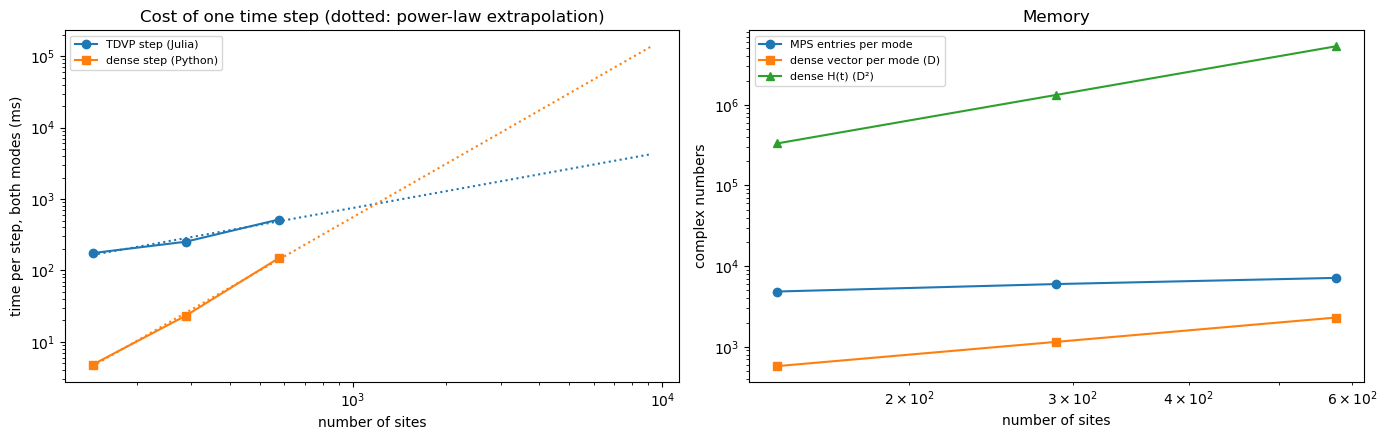

In [5]:
tt = {k: float(v) for k, v in np.genfromtxt("msh_tjunctions_tn_timing.csv", delimiter=",", names=True, dtype=None, encoding=None)}
pt = {k: np.asarray(v) for k, v in np.load(os.path.join(PY_DIR, "timing_kwant.npz")).items()}
print(f"{'run (both modes)':26s} {'steps':>7s} {'TDVP (Julia)':>13s} {'dense (Python)':>15s} {'ratio':>7s}")
for kind, key in (("Z", "Z"), ("X", "X400"), ("F", "F")):
    n = int(tt[f"steps_{kind}"])
    t_tn = tt[f"tdvp_{kind}_A"] + tt[f"tdvp_{kind}_B"]
    t_py = float(pt[f"time_{key}_fusion"]) + (float(pt[f"time_{key}_gate"]) if f"time_{key}_gate" in pt else 0.0)
    lbl = {"Z": "Z gate + fusion", "X": "X (rot_Tx = 400) + fusion", "F": "fusion only"}[kind]
    print(f"{lbl:26s} {n:7d} {t_tn / 60:10.1f} min {t_py / 60:12.1f} min {t_tn / t_py:6.0f}×")
print(f"{'zero modes':26s} {'':7s} {(tt['dmrg_ldos'] + tt['dmrg_mzm']):11.0f} s {float(pt['eigh']):13.2f} s"
      f"   (DMRG + refinement vs one eigh)")

sites = np.array([tt[f"bench_sites_L{L}"] for L in (4, 5, 6)])
t_tn = 2 * np.array([tt[f"bench_step_L{L}"] for L in (4, 5, 6)])            # both modes
t_py = pt["bench_step"]; t_eigh = pt["bench_eigh"]
mps = np.array([tt[f"bench_mps_size_L{L}"] for L in (4, 5, 6)])
assert np.array_equal(sites, pt["bench_sites"])
p_tn = np.polyfit(np.log(sites), np.log(t_tn), 1)[0]; p_py = np.polyfit(np.log(sites), np.log(t_py), 1)[0]
print(f"\n{'sites':>6s} {'D':>6s} {'TDVP step':>11s} {'dense step':>11s} {'eigh':>9s} {'MPS entries':>12s} {'dense vector':>13s} {'dense H':>10s}")
for i in range(3):
    D = 4 * int(sites[i])
    print(f"{int(sites[i]):6d} {D:6d} {1e3 * t_tn[i]:8.1f} ms {1e3 * t_py[i]:8.1f} ms {t_eigh[i]:7.2f} s {int(mps[i]):12d} {D:13d} {D * D:10d}")
print(f"\nlocal power law, time ∝ sites^p: TDVP p = {p_tn:.2f}, dense p = {p_py:.2f}")

ns = np.geomspace(sites[0], 16 * sites[-1], 60)
fit = lambda t: np.exp(np.polyval(np.polyfit(np.log(sites), np.log(t), 1), np.log(ns)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].loglog(sites, 1e3 * t_tn, "o-", label="TDVP step (Julia)")
ax[0].loglog(sites, 1e3 * t_py, "s-", label="dense step (Python)")
ax[0].loglog(ns, 1e3 * fit(t_tn), ":", color="C0"); ax[0].loglog(ns, 1e3 * fit(t_py), ":", color="C1")
ax[0].set(xlabel="number of sites", ylabel="time per step, both modes (ms)", title="Cost of one time step (dotted: power-law extrapolation)")
ax[0].legend(fontsize=8)
ax[1].loglog(sites, mps, "o-", label="MPS entries per mode")
ax[1].loglog(sites, 4 * sites, "s-", label="dense vector per mode (D)")
ax[1].loglog(sites, (4 * sites) ** 2, "^-", label="dense H(t) (D²)")
ax[1].set(xlabel="number of sites", ylabel="complex numbers", title="Memory"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. Summary

Every row, with its difference and its tolerance.

21 of 21 comparisons within tolerance


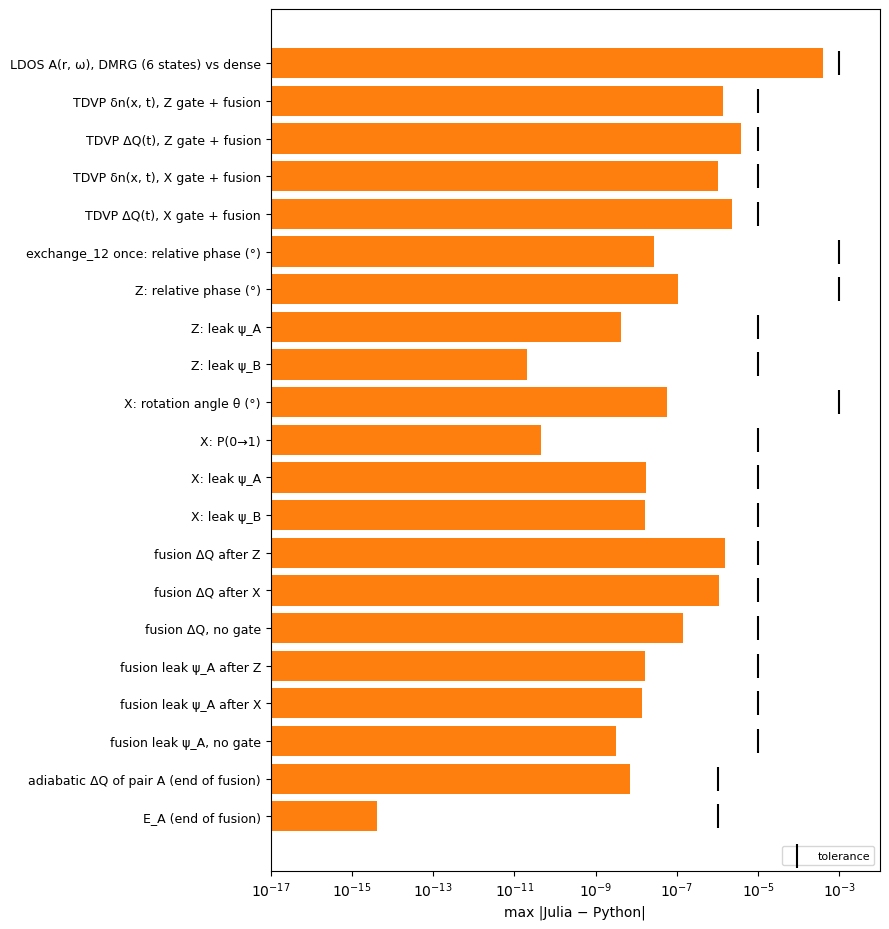

In [6]:
ok = sum(d <= tol for _, d, tol in rows)
print(f"{ok} of {len(rows)} comparisons within tolerance")
for name, d, tol in rows:
    if d > tol:
        print(f"  ✗ {name}: {d:.1e} > {tol:.0e}")

fig, ax = plt.subplots(figsize=(9, 0.4 * len(rows) + 1))
yy = np.arange(len(rows))[::-1]
ax.barh(yy, [max(d, 1e-17) for _, d, _ in rows], color="tab:orange")
ax.scatter([tol for *_, tol in rows], yy, marker="|", s=300, color="k", label="tolerance")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e-2)
ax.set_yticks(yy); ax.set_yticklabels([name for name, _, _ in rows], fontsize=9)
ax.set_xlabel("max |Julia − Python|"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()